# 항공기 도착 지연 예측 (Airplane Delay Prediction.ipynb)

데이터 링크: https://drive.google.com/file/d/18vomowszCkVEG8klfC1JhoYblA8sD0Ki/view

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor


### 1. 데이터 불러오기

In [3]:
DATA_DIR = Path("./data")

FLIGHTS_PATH = DATA_DIR / 'flights.csv'
AIRPORTS_PATH = DATA_DIR / 'airports.csv'
WEATHER_PATH = DATA_DIR / 'weather.csv'
AIRLINES_PATH = DATA_DIR / 'airlines.csv'
PLANES_PATH = DATA_DIR / 'planes.csv'
TZONE_META_PATH = DATA_DIR / 'tzone_meta.csv'

flights = pd.read_csv(FLIGHTS_PATH)
airports = pd.read_csv(AIRPORTS_PATH)
weather = pd.read_csv(WEATHER_PATH)
airlines = pd.read_csv(AIRLINES_PATH)
planes = pd.read_csv(PLANES_PATH)
tzone_meta = pd.read_csv(TZONE_META_PATH)

print('flights :', flights.shape)
print('airports:', airports.shape)
print('weather :', weather.shape)

flights : (303748, 19)
airports: (1333, 8)
weather : (26201, 15)


### 2. 날씨 데이터 결측치 확인
`isna().sum()` 으로 컬럼별 결측시 확인. 0보타 큰 컬럼 출력

In [4]:
# 컬럼별 결측치 개수 계산
missing_count = weather.isna().sum()

# 결측치가 1개 이상인 컬럼만 출력
missing_columns = missing_count[missing_count > 0]

print(missing_columns)

temp          25642
dewp          25642
humid         25642
wind_dir       2661
wind_speed     2647
wind_gust      2647
precip        24831
pressure      25768
visib            11
dtype: int64


### 3. 시간 순서 기준으로 보간
공항별 데이터를 시간순으로 정렬한 뒤, 인접한 시간대의 관측값을 기준으로 선형 보간

In [5]:
# 시간 컬럼을 datetime으로 변환하고, 공항·시간 기준으로 정렬
weather = weather.copy()

weather["time_hour"] = pd.to_datetime(weather["time_hour"])

weather = weather.sort_values(
    ["origin", "time_hour"]
).reset_index(drop=True)

null_weather_cols = [
    "temp",
    "dewp",
    "humid",
    "wind_dir",
    "wind_speed",
    "wind_gust",
    "precip",
    "pressure",
    "visib",
]

ewr = weather[weather["origin"] == "EWR"].copy()
jfk = weather[weather["origin"] == "JFK"].copy()
lga = weather[weather["origin"] == "LGA"].copy()


ewr[null_weather_cols] = ewr[null_weather_cols].interpolate(
    method="linear",
    limit_direction="both",
)

jfk[null_weather_cols] = jfk[null_weather_cols].interpolate(
    method="linear",
    limit_direction="both",
)

lga[null_weather_cols] = lga[null_weather_cols].interpolate(
    method="linear",
    limit_direction="both",
)

weather = pd.concat(
    [ewr, jfk, lga],
    ignore_index=True,
)

weather = weather.sort_values(
    ["origin", "time_hour"]
).reset_index(drop=True)

print("보간 후 날씨 데이터 결측치 개수")
print(weather[null_weather_cols].isnull().sum())

보간 후 날씨 데이터 결측치 개수
temp          0
dewp          0
humid         0
wind_dir      0
wind_speed    0
wind_gust     0
precip        0
pressure      0
visib         0
dtype: int64


### 4. 공항/날씨 병합
- `concat` 은 같은 형태의 표를 위아래로 붙일 때 사용
- `merge` 는 공통키를 기준으로 열을 연결할 때 사용

In [6]:
for col in ['year', 'month', 'day', 'hour']:
    weather[col] = weather[col].astype(int)
    flights[col] = flights[col].astype(int)
    
weather_dep = weather[
    [
        "origin",
        "year",
        "month",
        "day",
        "hour",
        "temp",
        "dewp",
        "humid",
        "wind_dir",
        "wind_speed",
        "wind_gust",
        "precip",
        "pressure",
        "visib",
    ]
].copy()

weather_dep.columns = [
    "origin",
    "year",
    "month",
    "day",
    "hour",
    "dep_temp",
    "dep_dewp",
    "dep_humid",
    "dep_wind_dir",
    "dep_wind_speed",
    "dep_wind_gust",
    "dep_precip",
    "dep_pressure",
    "dep_visib",
]

flights_merged = flights.merge(
    weather_dep,
    on=["origin", "year", "month", "day", "hour"],
    how="left",
)

weather_arr = weather[
    [
        "origin",
        "year",
        "month",
        "day",
        "hour",
        "temp",
        "dewp",
        "humid",
        "wind_dir",
        "wind_speed",
        "wind_gust",
        "precip",
        "pressure",
        "visib",
    ]
].copy()

weather_arr.columns = [
    "dest",
    "year",
    "month",
    "day",
    "hour",
    "arr_temp",
    "arr_dewp",
    "arr_humid",
    "arr_wind_dir",
    "arr_wind_speed",
    "arr_wind_gust",
    "arr_precip",
    "arr_pressure",
    "arr_visib",
]

flights_merged = flights_merged.merge(
    weather_arr,
    on=["dest", "year", "month", "day", "hour"],
    how="left",
)

print("출발 공항 날씨 결측치")
print(flights_merged["dep_temp"].isnull().sum())

print("도착 공항 날씨 결측치")
print(flights_merged["arr_temp"].isnull().sum())

출발 공항 날씨 결측치
731
도착 공항 날씨 결측치
303748


데이터 셋에서 날씨 관측 공항은 EWR, JFK, LGA 뿐이다.
`flights.dest` 에는 이 공항들이 존재하지 않음. 따라서 `left merge` 를 실행하면 `arr_weather_` 는 전부 결측치가 된다.
따라서 나중에 모델 입력에서는 제거해야 한다.

### 5. 타깃 변수 정의
예측하려는 값이 "도착 지연 시간"이므로 타겟 변수는 `arr_delay` 로 설정
- `arr_delay` 는 예정 도착 시각과 실제 도착 시각의 차이를 분 단위로 나타낸 값


### 6. 모델 학습에 불필요한 컬럼 제거, 변수 구성

In [7]:
target = "arr_delay"

drop_columns = [
    "arr_delay",      
    "dep_time",       
    "arr_time",      
    "air_time",      
    "year",         
    "time_hour",      
    "flight",         
    "tailnum",        
    "arr_temp",       
    "arr_dewp",
    "arr_humid",
    "arr_wind_dir",
    "arr_wind_speed",
    "arr_wind_gust",
    "arr_precip",
    "arr_pressure",
    "arr_visib",
]

model_df = flights_merged.dropna(subset=["arr_delay"]).copy()

X = model_df.drop(columns=drop_columns)
y = model_df["arr_delay"]

print("X 크기:", X.shape)
print("y 크기:", y.shape)

X 크기: (294896, 20)
y 크기: (294896,)


**제거 이유**

- `arr_delay` : 모델이 예측해야 하는 target
- `dep_time` : 실제 출발 시각
- `arr_time`, `air_time` : 실제 도착 뒤에 알 수 있는 결과값
- `year` : 모든 값이 2017로 동일
- `time_hour` : 이미 년, 월, 일, 시로 나누어져 있음
- `flight`, `tailnum` : 단순 식별자
- `arr_weather_` : 도착 공항 날씨 원본이 없어 결측치기 때문

### 7. 데이터 분리
학습, 테스트를 8:2로 분리

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

print("X_train", X_train.shape)
print("X_test", X_test.shape)
print("y_train", y_train.shape)
print("y_test", y_test.shape)

X_train (235916, 20)
X_test (58980, 20)
y_train (235916,)
y_test (58980,)


### 8. XGBoost Regressor 모델 학습

In [9]:
# 수치형·범주형 컬럼 구분
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# 수치형: 결측치 중앙값 처리
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

# 범주형: 결측치 최빈값 처리 + 원-핫 인코딩
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

# 전처리 구성
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

# 전처리 + XGBoost Regressor 모델
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(random_state=2026)),
    ]
)

# 모델 학습
model.fit(X_train, y_train)

print("XGBoost Regressor 학습 완료")

XGBoost Regressor 학습 완료


In [10]:
# 1. 테스트 데이터 예측
y_pred = model.predict(X_test)

# 2. 평가 지표 계산
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# 3. 평가 지표 출력
print("XGBoost Regressor 평가 결과")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2   : {r2:.4f}")

XGBoost Regressor 평가 결과
MAE  : 11.86
MSE  : 407.00
RMSE : 20.17
R2   : 0.8698


### 인사이트
XGBoost Regressor의 테스트 데이터 평가 결과, MAE는 11.86분, MSE는 407.00, RMSE는 20.17분, R2는 0.8698이다. 
- MAE가 약 11.86분이라는 것은 모델의 도착 지연 시간 예측값이 실제값과 평균적으로 약 11.86분 차이 난다는 의미 
- RMSE는 약 20.17분으로 MAE보다 크게 나타났으며, 이는 일부 항공편에서 상대적으로 큰 예측 오차가 발생했음을 의미
- MSE는 오차를 제곱하여 계산하기 때문에 큰 지연 오차의 영향을 크게 받는다.  
- R2는 0.8698로, 모델이 도착 지연 시간의 변동을 약 86.98%로 예측했다는 의미. 따라서 실제 출발 지연 시간(dep_delay), 항공편 일정, 출발 공항 날씨 등의 입력 변수가 도착 지연 시간 예측에 효과적으로 활용되었음을 확인할 수 있다.

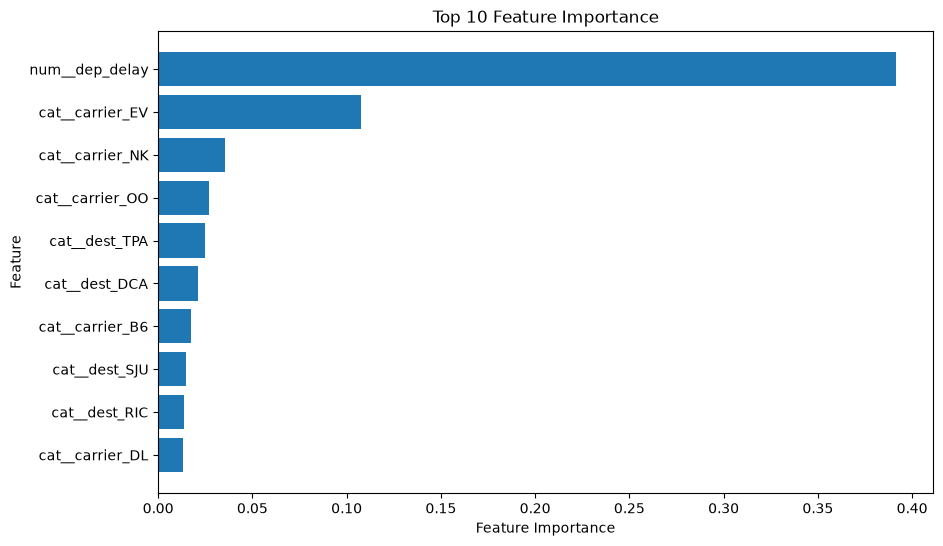

In [11]:
# Pipeline 안의 전처리기와 XGBoost 모델 꺼내기
preprocessor = model.named_steps["preprocessor"]
xgb_model = model.named_steps["model"]

# 원-핫 인코딩 후의 Feature 이름 가져오기
feature_names = preprocessor.get_feature_names_out()

# Feature Importance 데이터프레임 만들기
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_,
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False,
)
top_10 = importance_df.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_10["Feature"],
    top_10["Importance"],
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importance")
plt.show()

In [12]:
top_2 = importance_df.head(2)

print("가장 중요한 Feature 2개")
print(top_2.to_string(index=False))

가장 중요한 Feature 2개
        Feature  Importance
 num__dep_delay    0.391578
cat__carrier_EV    0.107426
